### Environment & Synthetic Bank Customer Data Creation

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

sns.set_theme(style="whitegrid")
%matplotlib inline

np.random.seed(42)
n_samples = 1000

data = {
    'Customer_ID': [f'CUST_{10000 + i}' for i in range(n_samples)],
    'Credit_Score': np.random.normal(loc=650, scale=80, size=n_samples).astype(int),
    'Age': np.random.randint(18, 70, size=n_samples),
    'Tenure': np.random.randint(0, 11, size=n_samples),
    'Balance': np.random.exponential(scale=50000, size=n_samples).round(2),
    'Num_Products': np.random.choice([1, 2, 3, 4], size=n_samples, p=[0.5, 0.35, 0.1, 0.05]),
    'Has_CrCard': np.random.choice([0, 1], size=n_samples, p=[0.3, 0.7]),
    'Is_Active': np.random.choice([0, 1], size=n_samples, p=[0.45, 0.55]),
    'Estimated_Salary': np.random.uniform(20000, 150000, size=n_samples).round(2),
}

df = pd.DataFrame(data)

# Generate realistic target 'Exited' correlated with Age, Balance, and Active status
churn_prob = (
    0.1 
    + (df['Age'] / 100) * 0.35 
    + (df['Balance'] / 150000) * 0.15 
    - (df['Is_Active'] * 0.15)
)
churn_prob = np.clip(churn_prob, 0.02, 0.95)
df['Exited'] = (np.random.rand(n_samples) < churn_prob).astype(int)

print("Dataset preview:")
df.head()

Dataset preview:


,Customer_ID,Credit_Score,Age,Tenure,Balance,Num_Products,Has_CrCard,Is_Active,Estimated_Salary,Exited
0,CUST_10000,689,61,3,23685.62,2,0,1,119732.19,0
1,CUST_10001,638,66,3,137695.14,2,1,1,146449.54,0
2,CUST_10002,701,57,5,56218.06,2,1,1,57159.39,0
3,CUST_10003,771,28,9,6166.19,2,0,1,29244.39,0
4,CUST_10004,631,20,9,2160.60,2,1,1,64935.40,0


### Data Diagnostics, Missing Value Handling & Aggregations

In [2]:
print("--- Data Structure ---")
print(df.info())

# Aggregation table by Activity Status and Products
agg_summary = df.groupby(['Is_Active', 'Num_Products']).agg(
    Customer_Count=('Customer_ID', 'count'),
    Mean_Balance=('Balance', 'mean'),
    Mean_Age=('Age', 'mean'),
    Churn_Rate=('Exited', 'mean')
).round(3)

print("\n--- Cohort Aggregation Summary ---")
print(agg_summary)

--- Data Structure ---
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Customer_ID       1000 non-null   str    
 1   Credit_Score      1000 non-null   int64  
 2   Age               1000 non-null   int32  
 3   Tenure            1000 non-null   int32  
 4   Balance           1000 non-null   float64
 5   Num_Products      1000 non-null   int64  
 6   Has_CrCard        1000 non-null   int64  
 7   Is_Active         1000 non-null   int64  
 8   Estimated_Salary  1000 non-null   float64
 9   Exited            1000 non-null   int64  
dtypes: float64(2), int32(2), int64(5), str(1)
memory usage: 80.2 KB
None

--- Cohort Aggregation Summary ---
                        Customer_Count  Mean_Balance  Mean_Age  Churn_Rate
Is_Active Num_Products                                                    
0         1                        241     54042.154    42

### Visual Analytics & Correlation Matrix

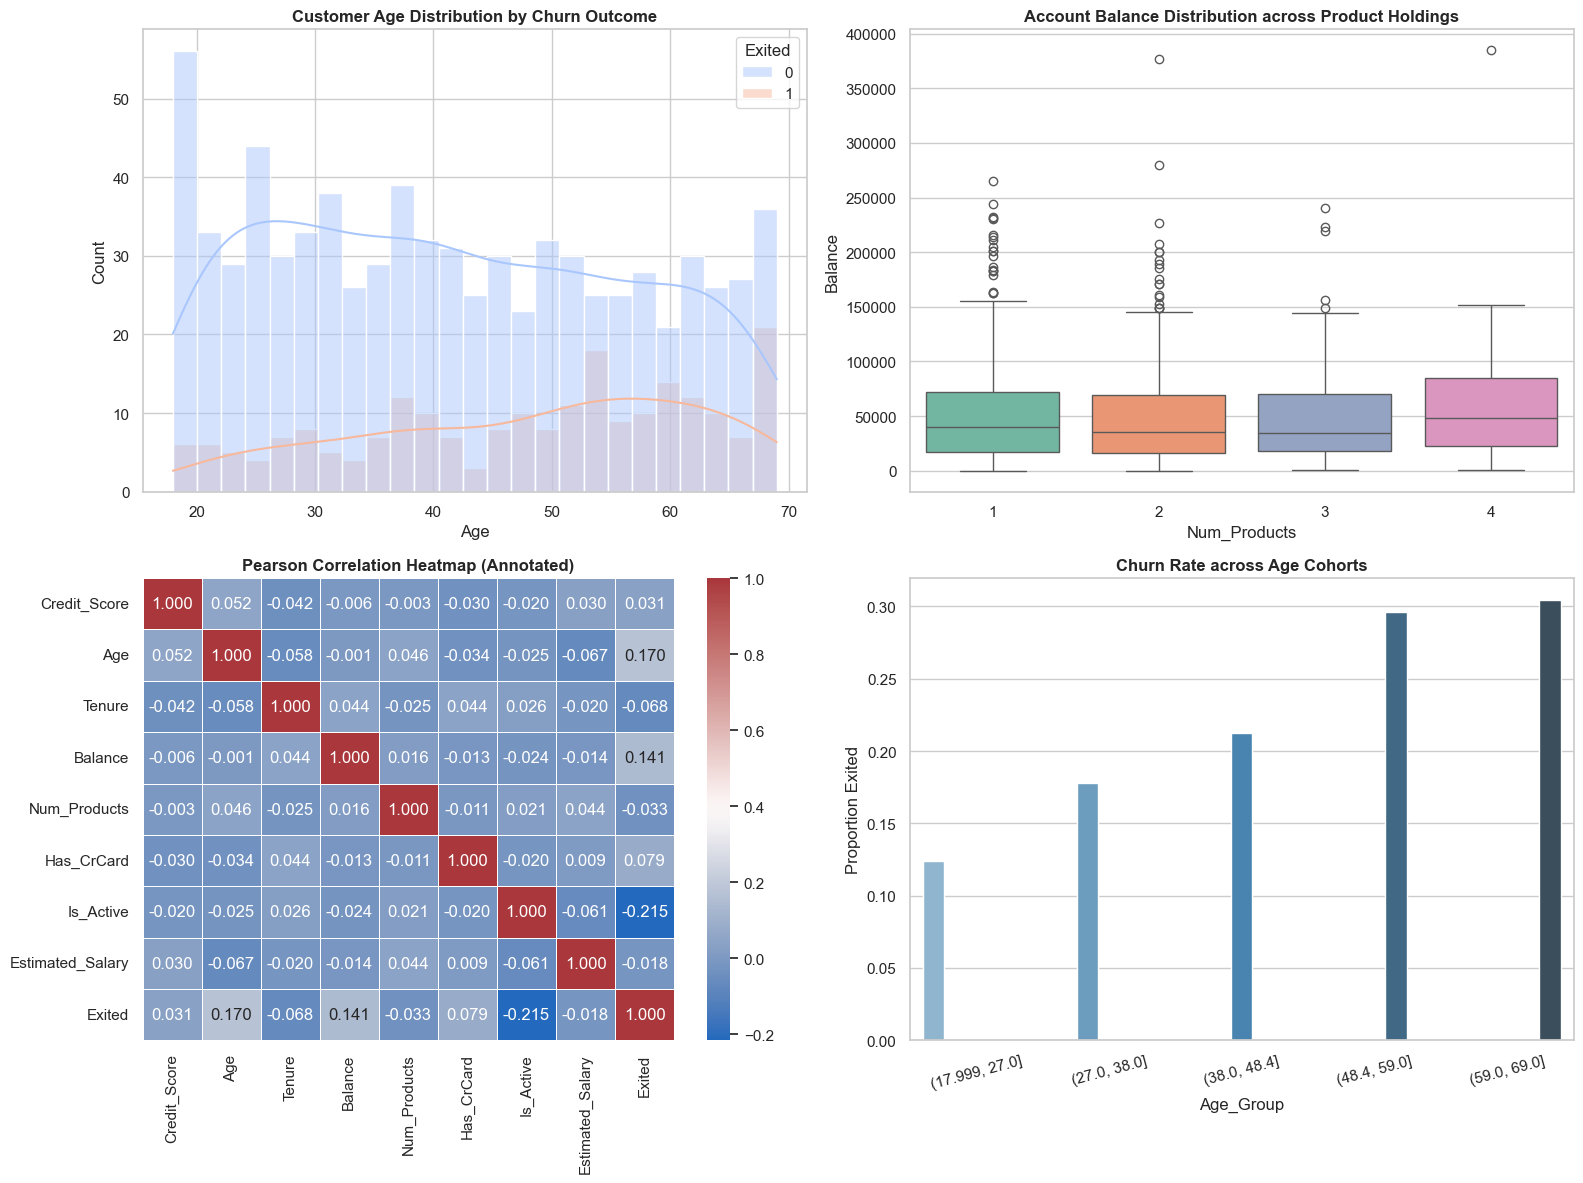


Exact Numerical Correlation Matrix:
                  Credit_Score     Age  Tenure  Balance  Num_Products  \
Credit_Score            1.0000  0.0523 -0.0418  -0.0060       -0.0026   
Age                     0.0523  1.0000 -0.0575  -0.0008        0.0456   
Tenure                 -0.0418 -0.0575  1.0000   0.0442       -0.0252   
Balance                -0.0060 -0.0008  0.0442   1.0000        0.0162   
Num_Products           -0.0026  0.0456 -0.0252   0.0162        1.0000   
Has_CrCard             -0.0305 -0.0335  0.0436  -0.0128       -0.0110   
Is_Active              -0.0196 -0.0249  0.0264  -0.0241        0.0209   
Estimated_Salary        0.0302 -0.0670 -0.0203  -0.0136        0.0440   
Exited                  0.0314  0.1699 -0.0682   0.1408       -0.0328   

                  Has_CrCard  Is_Active  Estimated_Salary  Exited  
Credit_Score         -0.0305    -0.0196            0.0302  0.0314  
Age                  -0.0335    -0.0249           -0.0670  0.1699  
Tenure                0.0436

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Age Distribution by Churn Status
sns.histplot(data=df, x='Age', hue='Exited', kde=True, ax=axes[0, 0], palette='coolwarm', bins=25)
axes[0, 0].set_title('Customer Age Distribution by Churn Outcome', fontsize=12, fontweight='bold')

# 2. Account Balance by Number of Products
sns.boxplot(data=df, x='Num_Products', y='Balance', hue='Num_Products', legend=False, ax=axes[0, 1], palette='Set2')
axes[0, 1].set_title('Account Balance Distribution across Product Holdings', fontsize=12, fontweight='bold')

# 3. Correlation Heatmap
numeric_cols = ['Credit_Score', 'Age', 'Tenure', 'Balance', 'Num_Products', 'Has_CrCard', 'Is_Active', 'Estimated_Salary', 'Exited']
corr_matrix = df[numeric_cols].corr().round(4)
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='vlag', ax=axes[1, 0], cbar=True, linewidths=0.5)
axes[1, 0].set_title('Pearson Correlation Heatmap (Annotated)', fontsize=12, fontweight='bold')

# 4. Churn Rate by Age Deciles
df['Age_Group'] = pd.qcut(df['Age'], q=5)
age_churn = df.groupby('Age_Group')['Exited'].mean().reset_index()
sns.barplot(
    data=age_churn, 
    x='Age_Group', 
    y='Exited', 
    hue='Age_Group', 
    legend=False, 
    ax=axes[1, 1], 
    palette='Blues_d'
)
axes[1, 1].set_title('Churn Rate across Age Cohorts', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('Proportion Exited')
axes[1, 1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.savefig('task_4_visualizations.png', dpi=300)
plt.show()

print("\nExact Numerical Correlation Matrix:")
print(corr_matrix)

### Predictive Modeling with Scikit-Learn

In [6]:
X = df[numeric_cols].drop(columns=['Exited'])
y = df['Exited']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train_scaled, y_train)

y_pred = clf.predict(X_test_scaled)
y_prob = clf.predict_proba(X_test_scaled)[:, 1]

print("--- Scikit-Learn Classification Report ---")
print(classification_report(y_test, y_pred, digits=4))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}")

--- Scikit-Learn Classification Report ---
              precision    recall  f1-score   support

           0     0.7853    0.9615    0.8646       156
           1     0.3333    0.0682    0.1132        44

    accuracy                         0.7650       200
   macro avg     0.5593    0.5149    0.4889       200
weighted avg     0.6859    0.7650    0.6993       200

ROC-AUC Score: 0.6203
